# Lecture 11

In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

### The Monty Hall Problem is a Great Case to Simulate! ###

In [2]:
goats = make_array('first goat', 'second goat')
doors = make_array('car', 'first goat', 'second goat')
doors

array(['car', 'first goat', 'second goat'],
      dtype='<U11')

A goat is always revealed. First, we'll define a function that determines which goat is revealed.

In [3]:
def other_goat(x):
    if x == 'first goat':
        return 'second goat'
    elif x == 'second goat':
        return 'first goat'

In [4]:
make_array(other_goat('first goat'), other_goat('second goat'))

array(['second goat', 'first goat'],
      dtype='<U11')

In [5]:
def monty_hall():
    """Return 
    array([contestant's guess, what Monty reveals, what remains behind the other door])"""
    
    #Contest randonmly chooses one of the three doors
    contestant_choice = np.random.choice(doors)

    #Scenario #1 - Contestant chooses the first goat
    if contestant_choice == 'first goat':
        monty_choice = 'second goat'
        remaining_choice = 'car'
        
    #Scenario #2 - Contestant chooses the second goat
    elif contestant_choice == 'second goat':
        monty_choice = 'first goat'
        remaining_choice = 'car'
    
   #Scenario #3 - Contestant chooses the car
    elif contestant_choice == 'car':
        monty_choice = np.random.choice(goats)
        remaining_choice = other_goat(monty_choice)
        
    return make_array(contestant_choice, monty_choice, remaining_choice)

In [36]:
monty_hall()

array(['first goat', 'second goat', 'car'],
      dtype='<U11')

In [37]:
results = Table(make_array("Contestant's Choice", "Monty's Choice", "Remaining Choice"))
results

Contestant's Choice,Monty's Choice,Remaining Choice


In [38]:
for i in np.arange(10000):
    # There is a table vesrion of append that's slightly different than the np.append
    # This one just adds a new row onto the end
    results.append(monty_hall())
    

In [39]:
results.show(3)

Contestant's Choice,Monty's Choice,Remaining Choice
car,first goat,second goat
second goat,first goat,car
second goat,first goat,car


In [40]:
results.group("Contestant's Choice")

Contestant's Choice,count
car,3327
first goat,3296
second goat,3377


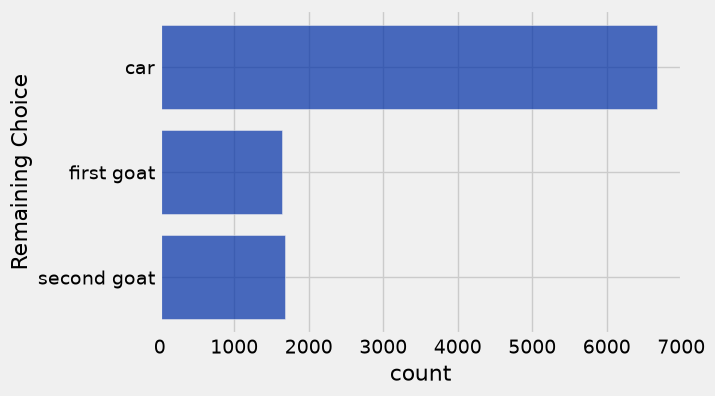

In [42]:
results.group("Remaining Choice").barh("Remaining Choice")

### Distributions

#### **Task (distributions)**: Create:
- The theoretical probability distribution of a six-sided die
- The observed probability distribution of a six-sided die after: 10, 100, 1,000 and 10,000 rolls.

**Theoretical distribution**

In [43]:
die = Table().with_column('Face', np.arange(1, 7))
die

Face
1
2
3
4
5
6


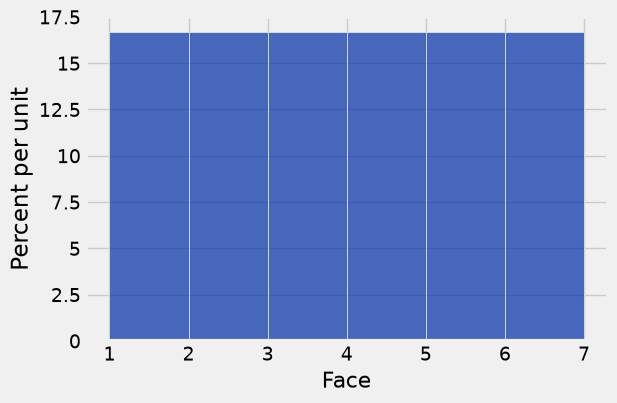

In [45]:
die.hist(bins=make_array(1,2,3,4,5,6,7))

**Observed distributions**

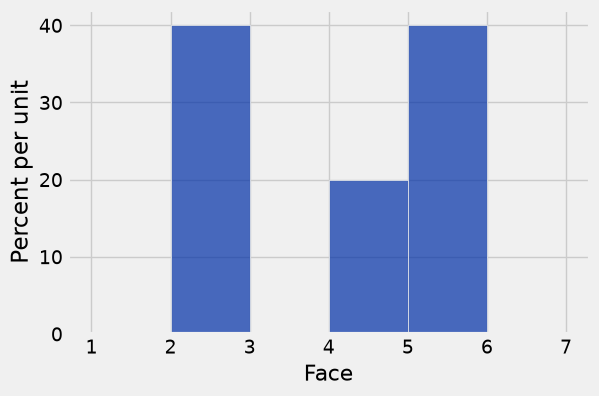

In [85]:
# Sampling from a table to make a table with random entries
die.sample(5).hist(bins=make_array(1,2,3,4,5,6,7))

In [84]:
# Sampling randomly from an array
np.random.choice(np.arange(1,7), 2)

array([1, 3])

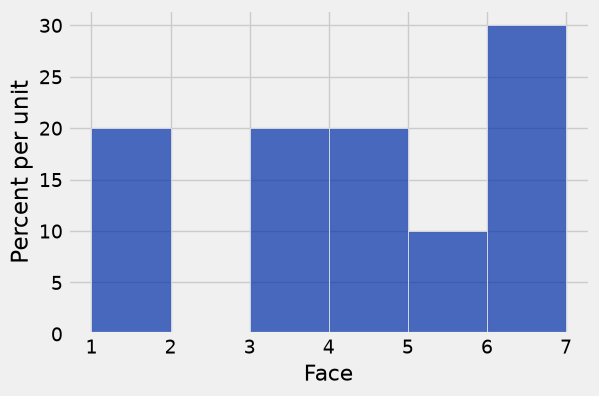

In [86]:
# Sampling from a table to make a table with random entries
die.sample(10).hist(bins=make_array(1,2,3,4,5,6,7))

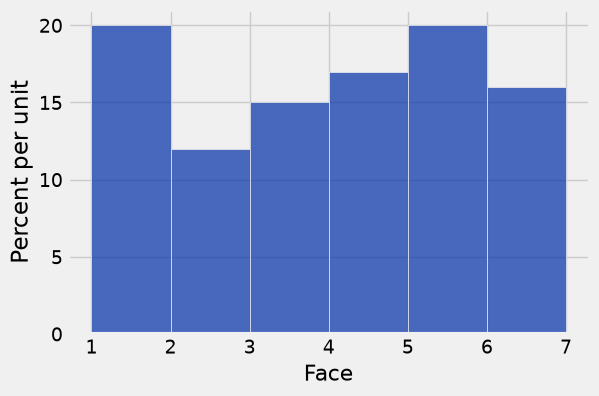

In [90]:
# Sampling from a table to make a table with random entries
die.sample(100).hist(bins=make_array(1,2,3,4,5,6,7))

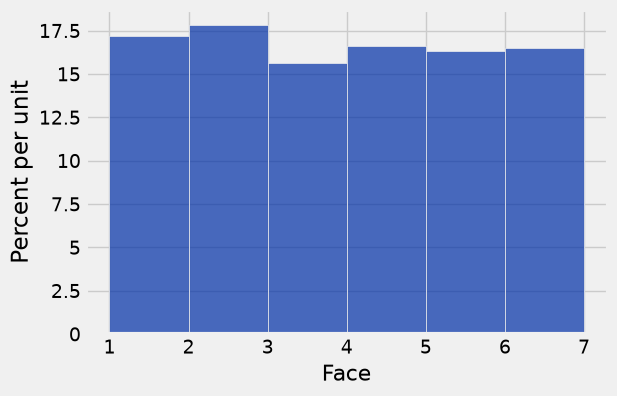

In [93]:
# Sampling from a table to make a table with random entries
die.sample(1000).hist(bins=make_array(1,2,3,4,5,6,7))

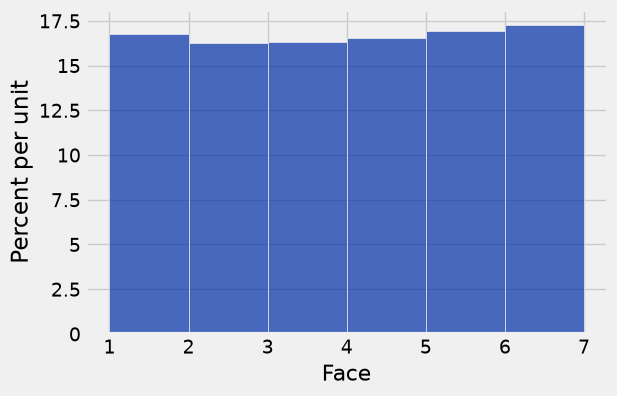

In [94]:
# Sampling from a table to make a table with random entries
die.sample(10000).hist(bins=make_array(1,2,3,4,5,6,7))

### Law of Large Numbers

In [95]:
united = Table.read_table('united.csv')
united = united.with_column('Row', np.arange(united.num_rows)).move_to_start('Row')
united

Row,Date,Flight Number,Destination,Delay
0,6/1/15,73,HNL,257
1,6/1/15,217,EWR,28
2,6/1/15,237,STL,-3
3,6/1/15,250,SAN,0
4,6/1/15,267,PHL,64
5,6/1/15,273,SEA,-6
6,6/1/15,278,SEA,-8
7,6/1/15,292,EWR,12
8,6/1/15,300,HNL,20
9,6/1/15,317,IND,-10


#### **Task (quantities)**: Find or create
- The median delay time (in minutes) across all United flights from 6/1/15 to 8/9/15.
- The observed distribution of median delay times after taking samples (*with replacement*) of: 10, 100, 1,000 and 10,000 randomly sampled flights.

In [100]:
min(united.column('Delay')), max(united.column('Delay'))

(-16, 580)

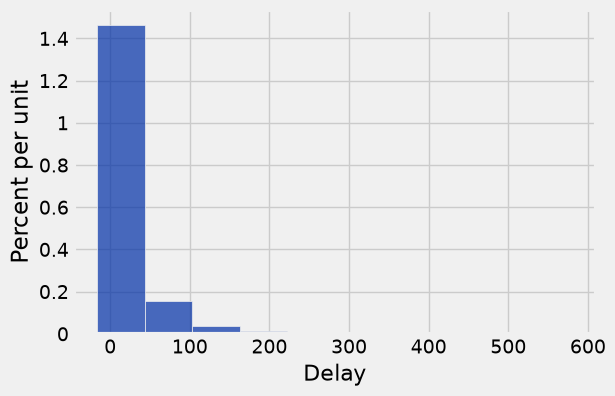

In [98]:
united.hist('Delay')

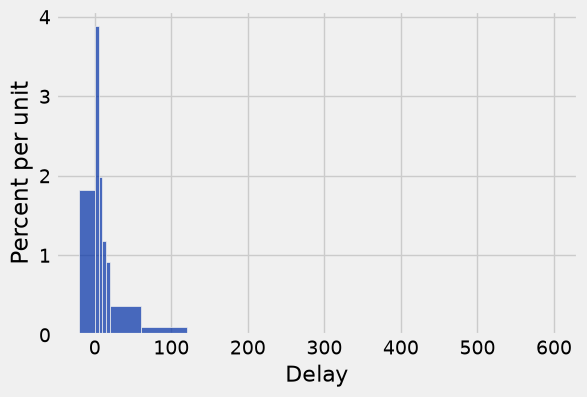

In [105]:
united.hist('Delay', bins=make_array(-20, 0, 5, 10, 15, 20, 60, 120, 600))

In [106]:
np.median(united.column('Delay'))

2.0

In [267]:
np.median(united.sample(10).column('Delay'))

0.0

In [237]:
np.median(united.sample(100).column('Delay'))

2.5

##### **Discussion** [1 min]: 
- What are the data type(s) of the input?
- What is the data type of the output?

In [268]:
def observed_sample_median_distribution(repetition_size, sample_size):

    observed_sample_medians = make_array()

    for i in np.arange(repetition_size):
        new_median = np.median(united.sample(sample_size).column('Delay'))
        observed_sample_medians = np.append(observed_sample_medians, new_median)

    return observed_sample_medians

##### **Discussion** [1 min]: How should I set the arguments to this function so that the LLN is invoked?

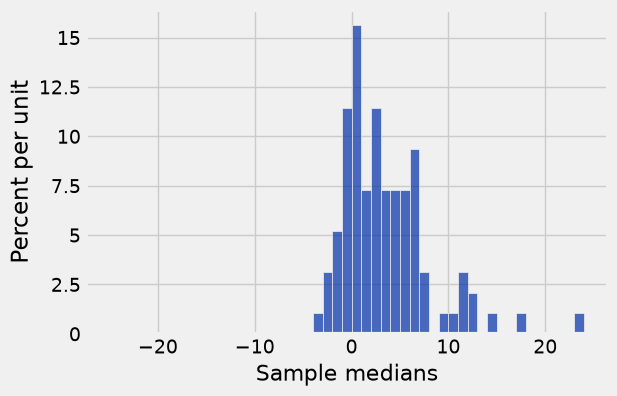

In [299]:
results = observed_sample_median_distribution(repetition_size=100,sample_size=10)
Table().with_column('Sample medians', results).hist(bins=np.arange(-25,25))

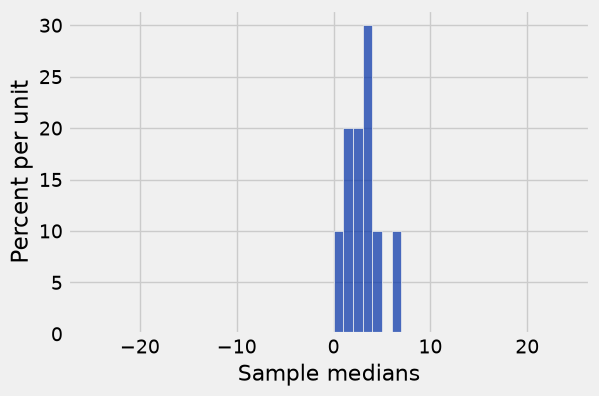

In [274]:
Table().with_column('Sample medians', results).hist(bins=np.arange(-25,25))

### The case of Robert Swain

In [300]:
population_proportions = make_array(.26, .74)
population_proportions

array([ 0.26,  0.74])

In [394]:
sample_proportions(100, population_proportions)

array([ 0.3,  0.7])

In [395]:
def panel_proportions():
    return sample_proportions(100, population_proportions).item(0)

In [406]:
panel_proportions()

0.33

In [408]:
panels = make_array()

for i in np.arange(10000):
    new_panel = panel_proportions() * 100
    panels = np.append(panels, new_panel)

In [409]:
panels

array([ 28.,  31.,  25., ...,  27.,  17.,  25.])

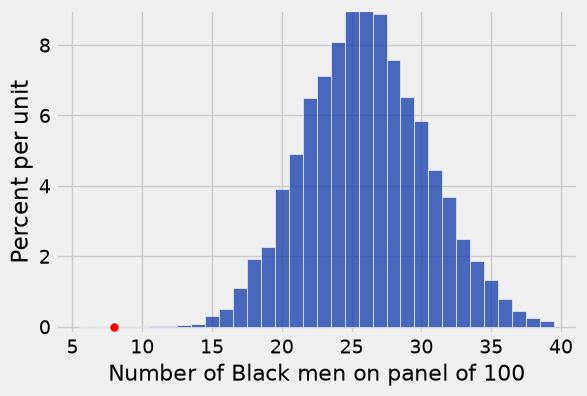

In [410]:
Table().with_column(
    'Number of Black men on panel of 100', panels
).hist(bins=np.arange(5.5,40.))

# Plotting details; ignore this code
plots.ylim(-0.002, 0.09)
plots.scatter(8, 0, color='red', s=30);